# 🧪 Research-driven improvements — experiment notebook
## ZAS Hackathon · Building Age · Team notebook 02

We test five upgrades suggested by the literature against our current Stage-2 method, **on exactly the same 10 support/query draws per n** used in `Building_Age_Final.ipynb`, so every number is directly comparable with the current results table.

| # | Upgrade | Source | Targets |
|---|---|---|---|
| 1 | **BCTS calibration before EM**, and a *safe* prior-correction rule | Alexandari et al., ICML 2020 — *Maximum likelihood with bias-corrected calibration is hard-to-beat at label shift adaptation* | n = 5, zero-shot |
| 2 | **TabPFN v2** few-shot learner (in-context learning) | Hollmann et al., *Nature* 2025 | n = 5, n = 25 |
| 3 | **Iterative, spatially consistent self-training** | TimeMatch (Nyborg et al., ISPRS 2022) — iterative pseudo-labelling for cross-region adaptation | all n |
| 4 | **CORAL** correlation alignment of Amsterdam features to Madrid | Sun et al., AAAI 2016 | zero-shot, low n |
| 5 | **Two-break change-points + steepest-transition features** | BATSCCD (2024); temporal template matching (Remote Sensing 2026) | class 3 vs 4 |

**Runs on both machines.** NVIDIA GPU detected → CatBoost on GPU and TabPFN enabled. No GPU → everything on CPU and TabPFN is skipped (set environment variable `TABPFN_CPU=1` to force it on CPU; slow).

**Inputs** (relative to this notebook): `features/madrid_features.parquet`, `features/amsterdam_features.parquet` (from `01-Our_Features.ipynb`) and `clean/*_yearly_clean.parquet` (from `00-Our_Data_Explained.ipynb`, needed only for upgrade 5).
**Outputs:** `experiments/` — all scores, the decision table and plots. Progress: `logs/experiments.log`.

In [1]:
try:
    import torch   # must load before LightGBM/CatBoost, otherwise its DLLs fail to initialise on Windows
except Exception:
    pass
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, time, os, warnings, subprocess, gc
from pathlib import Path
from scipy.ndimage import uniform_filter
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score
import lightgbm as lgb, catboost as cb
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})

DATA_DIR = next(Path(p) for p in ['data', '../data', '.'] if (Path(p) / 'madrid_train.parquet').exists())   # repo: put the parquet files in data/
LOG = DATA_DIR / 'logs' / 'experiments.log'; LOG.parent.mkdir(exist_ok=True); LOG.write_text('')
SEED, N_JOBS = 42, os.cpu_count()
CLASSES = np.array([1, 2, 3, 4]); PID = ['px_key', 'py_key']
N_SHOTS, N_DRAWS = [5, 25, 50, 100, 200], 10
SMOOTH = dict(alpha=0.5, size=3)      # tuned on Madrid OOF in Building_Age_Final.ipynb
SMOKE = os.environ.get('SMOKE') == '1' # quick crash test only — never used for reported numbers
if SMOKE: N_SHOTS, N_DRAWS = [5, 25], 1

def log(msg):
    s = f"[{time.strftime('%H:%M:%S')}] {msg}"; print(s, flush=True)
    with open(LOG, 'a', encoding='utf-8') as f: f.write(s + '\n')
def mf1(a, b): return f1_score(a, b, average='macro')

# ── device detection ─────────────────────────────────────────────────────────
def _nvidia():
    try: return subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'], capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception: return ''
GPU = _nvidia()
CAT_TASK = 'CPU'
if GPU:
    try: cb.CatBoostClassifier(iterations=3, task_type='GPU', verbose=0).fit(np.random.rand(100, 4), np.random.randint(0, 4, 100)); CAT_TASK = 'GPU'
    except Exception as e: log(f'CatBoost GPU unavailable: {e}')
TABPFN = None
if GPU or os.environ.get('TABPFN_CPU') == '1':
    try:
        from tabpfn import TabPFNClassifier
        _dev = 'cuda' if GPU else 'cpu'
        TabPFNClassifier(device=_dev, random_state=0).fit(np.random.rand(40, 5), np.random.randint(1, 5, 40)).predict_proba(np.random.rand(5, 5))
        TABPFN = _dev
    except Exception as e:
        log(f'TabPFN unavailable ({type(e).__name__}: {e}) — upgrade 2 will be skipped')
log(f"GPU: {GPU or 'none'} | CatBoost -> {CAT_TASK} | TabPFN -> {TABPFN or 'skipped'} | CPU threads {N_JOBS}")

[01:23:50] GPU: NVIDIA GeForce RTX 4060 | CatBoost -> GPU | TabPFN -> cuda | CPU threads 24


## 1 · Load the saved features and rebuild our current setup

Same per-city standardisation, same **TRANSFER** feature set (starter-like S + change-point D + robust index statistics), same training weights (coverage × balanced class weight), same base model (CatBoost, best zero-shot) and same support draws as the final notebook.

In [2]:
F = {c: pd.read_parquet(DATA_DIR / 'features' / f'{c.lower()}_features.parquet') for c in ['Madrid', 'Amsterdam']}
groups = json.load(open(DATA_DIR / 'features' / 'feature_groups.json'))
TRANSFER = groups['S'] + groups['D'] + [f'{ch}_{s}' for ch in ['NDVI', 'NDBI', 'MNDWI', 'BSI', 'NBR', 'NDTI', 'TCG', 'TCW'] for s in ['med', 'iqr', 'slope']]
ym, ya = F['Madrid'].age_class.to_numpy(), F['Amsterdam'].age_class.to_numpy()
PIX = {c: F[c][PID].reset_index(drop=True) for c in F}

def city_scale(X):
    mu = np.nanmean(X, 0); sd = np.nanstd(X, 0); sd[~(sd > 0)] = 1
    return ((X - mu) / sd).astype(np.float32)
def train_weights(yv, cov):
    cw = len(yv) / (4 * np.bincount(yv, minlength=5)[1:]); w = cov * cw[yv - 1]; return w / w.mean()
W_MAD = train_weights(ym, F['Madrid'].coverage.to_numpy())
MAD_PRIOR = np.bincount(ym, minlength=5)[1:] / len(ym)

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                  min_child_samples=20, n_jobs=N_JOBS, random_state=SEED, verbose=-1)
FT_PARAMS = dict(LGB_PARAMS, n_estimators=300)
ST_PARAMS = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=10, colsample_bytree=0.7, n_jobs=N_JOBS, verbose=-1)
def catboost(): return cb.CatBoostClassifier(iterations=60 if SMOKE else 400, depth=6, learning_rate=0.08, thread_count=N_JOBS, random_seed=SEED, verbose=0,
                                             task_type=CAT_TASK, **({'devices': '0'} if CAT_TASK == 'GPU' else {}))

# spatial helpers (identical to the final notebook)
def neigh(pix, v, size):
    x = (pix.px_key - pix.px_key.min()).to_numpy(); y_ = (pix.py_key - pix.py_key.min()).to_numpy()
    H, W = y_.max() + 1, x.max() + 1; ok = ~np.isnan(v)
    V = np.zeros((H, W)); M = np.zeros((H, W)); V[y_[ok], x[ok]] = v[ok]; M[y_[ok], x[ok]] = 1
    n = size ** 2; s = uniform_filter(V, size, mode='constant') * n - V; m = (uniform_filter(M, size, mode='constant') * n - M)[y_, x]
    return np.where(m > 0.5, s[y_, x] / np.maximum(m, 1), np.nan)
def smooth_proba(P, pix, alpha=SMOOTH['alpha'], size=SMOOTH['size']):
    N = np.column_stack([neigh(pix, P[:, k].astype(np.float64), size) for k in range(4)]); N = np.where(np.isnan(N), P, N)
    S = alpha * P + (1 - alpha) * N; return S / S.sum(1, keepdims=True)
def em_prior(P, prior_train=np.full(4, .25), iters=200, tol=1e-6):
    pi = prior_train.copy()
    for _ in range(iters):
        Q = P * (pi / prior_train); Q /= Q.sum(1, keepdims=True); new = Q.mean(0)
        if np.abs(new - pi).max() < tol: break
        pi = new
    return Q, pi
def sample_support(yv, n, seed):
    rng = np.random.default_rng(seed)
    s = np.concatenate([rng.choice(np.where(yv == k)[0], n, replace=False) for k in CLASSES])
    return s, np.setdiff1d(np.arange(len(yv)), s)
log(f"Loaded: Madrid {len(ym):,} px, Amsterdam {len(ya):,} px, TRANSFER = {len(TRANSFER)} features")

[01:23:51] Loaded: Madrid 76,263 px, Amsterdam 25,992 px, TRANSFER = 118 features


## 2 · Upgrade 5 — new change features (two breaks + steepest transition)

Our step-fit allows **one** jump. Real pixels often show **two**: demolition/clearing, then a new building (or construction, then a later renovation). We fit the best **three-level piecewise-constant** model to the gap-filled series (exhaustive search over all 861 pairs of break years, vectorised with cumulative sums) and add:
- `brk2_y1`, `brk2_y2` — the two break years; `brk2_d1`, `brk2_d2` — level changes; `brk2_strength` — variance explained; `brk2_extra` — gain over the one-break fit;
- `steep_year`, `steep_drop` — year and size of the steepest 3-year moving-average **drop in NDVI** (the "vegetation → built" transition used by temporal template matching), and the same for the steepest **rise in NDBI**.

Computed for NDVI, NDBI and tasselled-cap brightness from the clean yearly composites.

In [3]:
YEARS = np.arange(1984, 2026); BANDS = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
def cube_from_yearly(c):
    yr = pd.read_parquet(DATA_DIR / 'clean' / f'{c.lower()}_yearly_clean.parquet')
    wide = yr.set_index(PID + ['year'])[BANDS].unstack('year').reindex(pd.MultiIndex.from_frame(PIX[c]))
    B = {b: wide[b].reindex(columns=YEARS).to_numpy(np.float32) for b in BANDS}
    fill = lambda M: pd.DataFrame(M.T).interpolate(limit_direction='both').to_numpy(np.float32).T
    e = 1e-6
    ndvi = (B['NIR'] - B['Red']) / (B['NIR'] + B['Red'] + e); ndbi = (B['SWIR1'] - B['NIR']) / (B['SWIR1'] + B['NIR'] + e)
    refl = [B[b] * 2.75e-5 - 0.2 for b in BANDS]
    tcb = sum(w * r for w, r in zip([0.3029, 0.2786, 0.4733, 0.5599, 0.5080, 0.1872], refl))
    return {'NDVI': fill(ndvi), 'NDBI': fill(ndbi), 'TCB': fill(tcb.astype(np.float32))}

def two_break(Y):
    Y = Y.astype(np.float64); n, T = Y.shape
    cs = np.concatenate([np.zeros((n, 1)), np.cumsum(Y, 1)], 1)
    total_ss = ((Y - Y.mean(1, keepdims=True)) ** 2).sum(1) + 1e-12
    base = cs[:, T] ** 2 / T
    best = np.full(n, -np.inf); bi = np.zeros(n, int); bj = np.zeros(n, int)
    for i in range(2, T - 1):                       # segment 1 = [0,i), 2 = [i,j), 3 = [j,T), each ≥ 2 years
        js = np.arange(i + 2, T - 1)
        if len(js) == 0: continue
        s1 = cs[:, [i]] ** 2 / i
        s2 = (cs[:, js] - cs[:, [i]]) ** 2 / (js - i)
        s3 = (cs[:, [T]] - cs[:, js]) ** 2 / (T - js)
        gain = s1 + s2 + s3 - base[:, None]
        k = gain.argmax(1); g = gain[np.arange(n), k]
        upd = g > best; best[upd] = g[upd]; bi[upd] = i; bj[upd] = js[k[upd]]
    r = np.arange(n)
    l1 = cs[r, bi] / bi; l2 = (cs[r, bj] - cs[r, bi]) / (bj - bi); l3 = (cs[r, T] - cs[r, bj]) / (T - bj)
    return YEARS[bi], YEARS[bj], l2 - l1, l3 - l2, best / total_ss

def one_break_strength(Y):
    Y = Y.astype(np.float64); T = Y.shape[1]; k = np.arange(1, T)
    cs = np.cumsum(Y, 1)[:, :-1]; tot = Y.sum(1, keepdims=True)
    gain = k * (T - k) / T * (cs / k - (tot - cs) / (T - k)) ** 2
    return gain.max(1) / (Y.var(1) * T + 1e-12)

def new_change_features(c):
    t = time.time(); cub = cube_from_yearly(c); out = {}
    for ch, Y in cub.items():
        y1, y2, d1, d2, st = two_break(Y)
        out.update({f'{ch}_brk2_y1': y1, f'{ch}_brk2_y2': y2, f'{ch}_brk2_d1': d1, f'{ch}_brk2_d2': d2,
                    f'{ch}_brk2_strength': st, f'{ch}_brk2_extra': st - one_break_strength(Y)})
    for ch, sign in [('NDVI', -1), ('NDBI', 1)]:
        ma = pd.DataFrame(cub[ch].T).rolling(3, center=True, min_periods=1).mean().to_numpy().T
        d = sign * np.diff(ma, axis=1); j = d.argmax(1)
        out[f'{ch}_steep_year'] = YEARS[j + 1]; out[f'{ch}_steep_size'] = d[np.arange(len(d)), j]
    log(f"{c}: {len(out)} new change features ({time.time()-t:.0f}s)")
    return pd.DataFrame(out)

HAS_CLEAN = all((DATA_DIR / 'clean' / f'{c.lower()}_yearly_clean.parquet').exists() for c in ['Madrid', 'Amsterdam'])
NEW = {c: new_change_features(c) for c in ['Madrid', 'Amsterdam']} if HAS_CLEAN else None
if not HAS_CLEAN: log('clean/ folder missing — upgrade 5 skipped')

[01:23:59] Madrid: 22 new change features (8s)


[01:24:02] Amsterdam: 22 new change features (3s)


## 3 · Feature spaces

| Space | Amsterdam features fed to the Madrid model |
|---|---|
| `base` | TRANSFER set, per-city standardised (= current final notebook) |
| `coral` | `base`, then **CORAL**: Amsterdam features whitened with their own covariance and re-coloured with Madrid's, so both cities share the same feature correlations (no labels used) |
| `newfeat` | TRANSFER + the 22 new change features, per-city standardised |

In [4]:
def coral(Xs_src, Xs_tgt, eps=1.0):
    A, B = np.nan_to_num(Xs_src).astype(np.float64), np.nan_to_num(Xs_tgt).astype(np.float64)
    Cs = np.cov(A, rowvar=False) + eps * np.eye(A.shape[1]); Ct = np.cov(B, rowvar=False) + eps * np.eye(B.shape[1])
    def mpow(C, p):
        w, V = np.linalg.eigh(C); return (V * np.clip(w, 1e-8, None) ** p) @ V.T
    out = (B - B.mean(0)) @ mpow(Ct, -.5) @ mpow(Cs, .5) + A.mean(0)
    return np.where(np.isnan(Xs_tgt), np.nan, out).astype(np.float32)

SPACES = {}
Xm_b, Xa_b = city_scale(F['Madrid'][TRANSFER].to_numpy(np.float64)), city_scale(F['Amsterdam'][TRANSFER].to_numpy(np.float64))
SPACES['base'] = (Xm_b, Xa_b)
SPACES['coral'] = (Xm_b, coral(Xm_b, Xa_b))
if NEW is not None:
    SPACES['newfeat'] = (city_scale(np.hstack([F['Madrid'][TRANSFER].to_numpy(np.float64), NEW['Madrid'].to_numpy(np.float64)])),
                         city_scale(np.hstack([F['Amsterdam'][TRANSFER].to_numpy(np.float64), NEW['Amsterdam'].to_numpy(np.float64)])))
log('Feature spaces: ' + ', '.join(f'{k} ({v[0].shape[1]} features)' for k, v in SPACES.items()))

[01:24:03] Feature spaces: base (118 features), coral (118 features), newfeat (140 features)


## 4 · Zero-shot base models and Upgrade 1 — BCTS calibration

For each feature space we train CatBoost on all Madrid pixels and predict Amsterdam (zero-shot).

**BCTS (bias-corrected temperature scaling).** The paper's key finding: EM prior correction is only reliable if the probabilities are **calibrated**. We get Madrid out-of-fold CatBoost probabilities with spatial-block CV, then fit one temperature *T* and one bias per class *b* so that softmax(log p / T + b) matches Madrid's true labels. The calibrated model now reflects Madrid's real class mix, so EM starts from Madrid's prior and moves to Amsterdam's.

In [5]:
def bcts_fit(P, yv):
    L = np.log(P + 1e-9)
    def nll(th):
        Z = L / th[0] + th[1:]; Z -= Z.max(1, keepdims=True)
        return -(Z[np.arange(len(yv)), yv - 1] - np.log(np.exp(Z).sum(1))).mean()
    return minimize(nll, np.r_[1.0, np.zeros(4)], method='L-BFGS-B', bounds=[(0.05, 20)] + [(-5, 5)] * 4).x
def bcts_apply(P, th):
    Z = np.log(P + 1e-9) / th[0] + th[1:]; Z -= Z.max(1, keepdims=True); E = np.exp(Z); return E / E.sum(1, keepdims=True)

blocks = (PIX['Madrid'].px_key // 67).astype(str) + '_' + (PIX['Madrid'].py_key // 67).astype(str)
CV = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(ym)), ym, blocks))
PZ, TH = {}, {}
for sp, (Xm, Xa) in SPACES.items():
    t = time.time()
    PZ[sp] = catboost().fit(Xm, ym, sample_weight=W_MAD).predict_proba(Xa)
    oof = np.zeros((len(ym), 4))
    for tr, te in CV: oof[te] = catboost().fit(Xm[tr], ym[tr], sample_weight=W_MAD[tr]).predict_proba(Xm[te])
    TH[sp] = bcts_fit(oof, ym)
    log(f"{sp}: CatBoost zero-shot + 5 OOF fits done ({time.time()-t:.0f}s); BCTS T={TH[sp][0]:.2f}, b={np.round(TH[sp][1:], 2)}")

zs = []
for sp in SPACES:
    P0 = PZ[sp]; Pc = bcts_apply(P0, TH[sp])
    variants = {'raw': P0, 'EM (current)': em_prior(P0)[0], 'BCTS': Pc, 'BCTS → EM': em_prior(Pc, MAD_PRIOR)[0]}
    for name, P in variants.items():
        zs.append({'space': sp, 'variant': name, 'macro F1': mf1(ya, CLASSES[P.argmax(1)]),
                   'macro F1 + smoothing': mf1(ya, CLASSES[smooth_proba(P, PIX['Amsterdam']).argmax(1)])})
    log(f"{sp}: EM prior estimate after BCTS = {np.round(em_prior(Pc, MAD_PRIOR)[1], 2)} (true {np.round(np.bincount(ya, minlength=5)[1:] / len(ya), 2)})")
zs = pd.DataFrame(zs); zs.to_csv(OUT / 'zero_shot.csv', index=False)
zs.round(3)

[01:24:18] base: CatBoost zero-shot + 5 OOF fits done (15s); BCTS T=1.01, b=[-0.28  0.31  0.05 -0.08]


[01:24:33] coral: CatBoost zero-shot + 5 OOF fits done (15s); BCTS T=1.01, b=[-0.28  0.31  0.05 -0.08]


[01:24:48] newfeat: CatBoost zero-shot + 5 OOF fits done (16s); BCTS T=1.01, b=[-0.27  0.31  0.05 -0.08]


[01:24:49] base: EM prior estimate after BCTS = [0.06 0.45 0.32 0.17] (true [0.29 0.34 0.26 0.11])


[01:24:49] coral: EM prior estimate after BCTS = [0.01 0.45 0.41 0.13] (true [0.29 0.34 0.26 0.11])


[01:24:49] newfeat: EM prior estimate after BCTS = [0.05 0.46 0.31 0.17] (true [0.29 0.34 0.26 0.11])


,space,variant,macro F1,macro F1 + smoothing
0,base,raw,0.584,0.609
1,base,EM (current),0.450,0.459
2,base,BCTS,0.520,0.522
3,base,BCTS → EM,0.463,0.474
4,coral,raw,0.570,0.594
5,coral,EM (current),0.456,0.473
6,coral,BCTS,0.520,0.520
7,coral,BCTS → EM,0.447,0.462
8,newfeat,raw,0.593,0.615
9,newfeat,EM (current),0.459,0.467


## 5 · Few-shot members per draw

For every space, n and draw (seeds 0–9, identical to the final notebook) we compute the **members** once and cache them:
- `recal` — logistic recalibration of the zero-shot CatBoost probabilities (current);
- `ft` — LightGBM fine-tune on Madrid + weighted support (current);
- `st1` — one-round self-training (current);
- `st_iter` — **Upgrade 3**: 3 rounds, growing pseudo-label sets (300 → 600 → 1 000 per class), keeping only pseudo-labels whose class **agrees with the spatially smoothed prediction**, re-anchoring each round on the recalibration + fine-tune average;
- `tab` — **Upgrade 2**: TabPFN v2 trained in-context on the support set plus 250 confident, spatially consistent pseudo-labels per class; inputs = TRANSFER features + the Madrid model's 4 log-probabilities (GPU only).

In [6]:
def pseudo(P, s, per_class, pix, spatial=True):
    Ps = smooth_proba(P, pix) if spatial else P
    pool = np.setdiff1d(np.arange(len(P)), s); pred = P[pool].argmax(1)
    if spatial: pool, pred = pool[pred == Ps[pool].argmax(1)], pred[pred == Ps[pool].argmax(1)]
    idx, lab, w = [], [], []
    for k in range(4):
        cand = pool[pred == k]
        if len(cand): top = cand[np.argsort(-P[cand, k])[:per_class]]; idx.append(top); lab.append(np.full(len(top), k + 1)); w.append(P[top, k])
    return np.concatenate(idx), np.concatenate(lab), np.concatenate(w)

def members(sp, s, y_s, seed, pix):
    Xm, Xa = SPACES[sp]; L = np.log(PZ[sp] + 1e-6); out = {}
    out['recal'] = LogisticRegression(C=1.0, max_iter=3000).fit(L[s], y_s).predict_proba(L)
    w_s = np.full(len(s), 0.25 * W_MAD.sum() / len(s))
    out['ft'] = lgb.LGBMClassifier(**dict(FT_PARAMS, random_state=seed)).fit(np.vstack([Xm, Xa[s]]), np.r_[ym, y_s],
                                                                             sample_weight=np.r_[W_MAD, w_s]).predict_proba(Xa)
    anchor = (out['recal'] + out['ft']) / 2
    pi_, pl, pw = pseudo(anchor, s, 500, pix, spatial=False)
    st = lgb.LGBMClassifier(**dict(ST_PARAMS, random_state=seed)).fit(Xa[np.r_[s, pi_]], np.r_[y_s, pl], sample_weight=np.r_[np.full(len(s), 3.0), pw])
    out['st1'] = st.predict_proba(Xa)
    P = anchor
    for k in (300, 600, 1000):
        pi_, pl, pw = pseudo(P, s, k, pix, spatial=True)
        st = lgb.LGBMClassifier(**dict(ST_PARAMS, random_state=seed)).fit(Xa[np.r_[s, pi_]], np.r_[y_s, pl], sample_weight=np.r_[np.full(len(s), 3.0), pw])
        Pst = st.predict_proba(Xa); P = (anchor + Pst) / 2
    out['st_iter'] = Pst
    if TABPFN:
        Xt = np.hstack([np.nan_to_num(Xa), L]).astype(np.float32)
        pi_, pl, _ = pseudo((anchor + out['st_iter']) / 2, s, 250, pix, spatial=True)
        clf = TabPFNClassifier(device=TABPFN, random_state=seed, fit_mode='fit_with_cache')   # caches the training context across chunks
        clf.fit(Xt[np.r_[s, pi_]], np.r_[y_s, pl])   # predict in chunks: all 26k rows at once overflows 8 GB of GPU memory
        out['tab'] = np.vstack([clf.predict_proba(Xt[i:i + 2048]) for i in range(0, len(Xt), 2048)])
    return out

CACHE = {}
for sp in SPACES:
    t0 = time.time()
    for n in N_SHOTS:
        for d in range(N_DRAWS):
            s, q = sample_support(ya, n, d)
            CACHE[(sp, n, d)] = (s, q, members(sp, s, ya[s], d, PIX['Amsterdam']))
        m = CACHE[(sp, n, N_DRAWS - 1)][2]; q = CACHE[(sp, n, N_DRAWS - 1)][1]
        log(f"{sp} n={n:3d}: last draw — " + ' | '.join(f"{k} {mf1(ya[q], CLASSES[v[q].argmax(1)]):.3f}" for k, v in m.items()) +
            f"  ({(time.time()-t0)/60:.1f} min)")

[01:36:13] base n=  5: last draw — recal 0.553 | ft 0.594 | st1 0.640 | st_iter 0.644 | tab 0.588  (11.4 min)


[01:49:10] base n= 25: last draw — recal 0.626 | ft 0.645 | st1 0.669 | st_iter 0.654 | tab 0.665  (24.3 min)


[02:00:17] base n= 50: last draw — recal 0.632 | ft 0.663 | st1 0.693 | st_iter 0.692 | tab 0.685  (35.5 min)


[02:12:07] base n=100: last draw — recal 0.627 | ft 0.682 | st1 0.707 | st_iter 0.707 | tab 0.711  (47.3 min)


[02:25:34] base n=200: last draw — recal 0.632 | ft 0.700 | st1 0.709 | st_iter 0.711 | tab 0.713  (60.7 min)


...

[03:35:22] newfeat n=  5: last draw — recal 0.554 | ft 0.601 | st1 0.627 | st_iter 0.635 | tab 0.567  (12.2 min)


[03:47:59] newfeat n= 25: last draw — recal 0.637 | ft 0.653 | st1 0.671 | st_iter 0.663 | tab 0.666  (24.8 min)


[04:00:57] newfeat n= 50: last draw — recal 0.637 | ft 0.660 | st1 0.697 | st_iter 0.695 | tab 0.688  (37.7 min)


[04:14:45] newfeat n=100: last draw — recal 0.633 | ft 0.689 | st1 0.710 | st_iter 0.709 | tab 0.706  (51.5 min)


[04:30:23] newfeat n=200: last draw — recal 0.648 | ft 0.709 | st1 0.718 | st_iter 0.719 | tab 0.716  (67.2 min)


## 6 · Combining members — the variants

| Variant | Definition |
|---|---|
| `Ensemble` | mean(recal, ft, st1) — current |
| `FINAL (current)` | Ensemble → EM → spatial smoothing — current method |
| `FINAL safe-EM` | as FINAL, but EM only when n ≥ 25 (with 5 labels per class the recalibrated probabilities are too noisy to estimate a prior — Upgrade 1) |
| `FINAL damped-EM` | EM prior shrunk halfway towards uniform before re-weighting |
| `FINAL iter-ST` | mean(recal, ft, **st_iter**) → safe-EM → smoothing (Upgrade 3) |
| `FINAL + TabPFN` | mean(recal, ft, st_iter, **tab**) → safe-EM → smoothing (Upgrades 2 + 3) |
| `TabPFN alone` | tab → smoothing |

In [7]:
def damped_em(P):
    _, pi = em_prior(P); pi = (pi + .25) / 2
    Q = P * (pi / .25); return Q / Q.sum(1, keepdims=True)
def finish(P, n, mode='safe'):
    if mode == 'current' or (mode == 'safe' and n >= 25): P = em_prior(P)[0]
    elif mode == 'damped': P = damped_em(P)
    return smooth_proba(P, PIX['Amsterdam'])

VARIANTS = {
    'Ensemble':          lambda m, n: (m['recal'] + m['ft'] + m['st1']) / 3,
    'FINAL (current)':   lambda m, n: finish((m['recal'] + m['ft'] + m['st1']) / 3, n, 'current'),
    'FINAL safe-EM':     lambda m, n: finish((m['recal'] + m['ft'] + m['st1']) / 3, n, 'safe'),
    'FINAL damped-EM':   lambda m, n: finish((m['recal'] + m['ft'] + m['st1']) / 3, n, 'damped'),
    'FINAL iter-ST':     lambda m, n: finish((m['recal'] + m['ft'] + m['st_iter']) / 3, n, 'safe'),
}
if TABPFN:
    VARIANTS['FINAL + TabPFN'] = lambda m, n: finish((m['recal'] + m['ft'] + m['st_iter'] + m['tab']) / 4, n, 'safe')
    VARIANTS['TabPFN alone'] = lambda m, n: smooth_proba(m['tab'], PIX['Amsterdam'])

rows = []
for (sp, n, d), (s, q, m) in CACHE.items():
    for vname, fn in VARIANTS.items():
        rows.append({'space': sp, 'variant': vname, 'n': n, 'draw': d, 'macro F1': mf1(ya[q], CLASSES[fn(m, n)[q].argmax(1)])})
res = pd.DataFrame(rows); res.to_csv(OUT / 'few_shot_all.csv', index=False)
tab = res.groupby(['space', 'variant', 'n'])['macro F1'].agg(['mean', 'std']).unstack('n')
tab.round(3)

mean                                std                            
n                          5      25     50     100    200    5      25     50     100    200
space   variant                                                                              
base    Ensemble         0.624  0.663  0.685  0.704  0.719  0.026  0.015  0.006  0.004  0.004
        FINAL (current)  0.577  0.678  0.710  0.731  0.748  0.076  0.025  0.007  0.003  0.003
        FINAL + TabPFN   0.639  0.682  0.717  0.735  0.753  0.027  0.024  0.006  0.004  0.003
        FINAL damped-EM  0.618  0.682  0.709  0.727  0.744  0.042  0.019  0.007  0.003  0.004
        FINAL iter-ST    0.642  0.673  0.709  0.729  0.747  0.027  0.025  0.006  0.004  0.003
        FINAL safe-EM    0.640  0.678  0.710  0.731  0.748  0.027  0.025  0.007  0.003  0.003
        TabPFN alone     0.605  0.678  0.704  0.723  0.743  0.026  0.016  0.005  0.008  0.005
coral   Ensemble         0.632  0.656  0.673  0.688  0.703  0.012  0.007  0.005  0.006  0.003
        FINAL (current)  0.578  0.626  0.690  0.716  0.733  0.061  0.053  0.012  0.004  0.006
        FINAL + TabPFN   0.649  0.651  0.697  0.722  0.740  0.018  0.033  0.011  0.003  0.007
        FINAL damped-EM  0.633  0.665  0.697  0.715  0.733  0.024  0.012  0.006  0.004  0.003
        FINAL iter-ST    0.651  0.622  0.687  0.713  0.731  0.016  0.056  0.013  0.004  0.006
        FINAL safe-EM    0.652  0.626  0.690  0.716  0.733  0.014  0.053  0.012  0.004  0.006
        TabPFN alone     0.604  0.660  0.691  0.715  0.735  0.028  0.016  0.011  0.008  0.005
newfeat Ensemble         0.635  0.668  0.691  0.707  0.723  0.022  0.015  0.006  0.004  0.002
        FINAL (current)  0.623  0.683  0.718  0.736  0.753  0.050  0.022  0.004  0.003  0.002
        FINAL + TabPFN   0.649  0.686  0.724  0.740  0.757  0.025  0.019  0.004  0.005  0.002
        FINAL damped-EM  0.642  0.687  0.715  0.730  0.749  0.028  0.017  0.006  0.003  0.003
        FINAL iter-ST    0.651  0.680  0.717  0.733  0.751  0.025  0.018  0.005  0.004  0.002
        FINAL safe-EM    0.651  0.683  0.718  0.736  0.753  0.023  0.022  0.004  0.003  0.002
        TabPFN alone     0.615  0.680  0.709  0.725  0.746  0.030  0.017  0.004  0.006  0.004

## 7 · Decision table

Reference = `base / FINAL (current)` (it reproduces the final notebook's numbers). For each candidate we show the change in the **three prize metrics**; a candidate is **adopted** if it improves the n = 25 score *and* the average over the five sample sizes.

In [8]:
means = res.groupby(['space', 'variant', 'n'])['macro F1'].mean().unstack('n')
summ = pd.DataFrame({'average (5 n)': means.mean(1), 'peak': means.max(1), 'n = 25': means[25], 'n = 5': means[5]})
ref = summ.loc[('base', 'FINAL (current)')]
dec = summ.sub(ref, axis=1).add_prefix('Δ ')
dec = pd.concat([summ, dec], axis=1).sort_values('average (5 n)', ascending=False)
dec['adopt?'] = np.where((dec['Δ n = 25'] > 0.002) & (dec['Δ average (5 n)'] > 0.002), '✅', '—')
dec.to_csv(OUT / 'decision_table.csv')
log("Reference (base / FINAL current): " + ', '.join(f'n={n}: {means.loc[("base", "FINAL (current)"), n]:.3f}' for n in N_SHOTS))
best = dec.index[0]; log(f"Best configuration: {best} → average {dec.iloc[0]['average (5 n)']:.3f}, n=25 {dec.iloc[0]['n = 25']:.3f}")
dec.round(3)

[04:31:15] Reference (base / FINAL current): n=5: 0.577, n=25: 0.678, n=50: 0.710, n=100: 0.731, n=200: 0.748


[04:31:15] Best configuration: ('newfeat', 'FINAL + TabPFN') → average 0.711, n=25 0.686


average (5 n)   peak  n = 25  n = 5  Δ average (5 n)  Δ peak  Δ n = 25  Δ n = 5 adopt?
space   variant                                                                                                
newfeat FINAL + TabPFN           0.711  0.757   0.686  0.649            0.022   0.009     0.008    0.072      ✅
        FINAL safe-EM            0.708  0.753   0.683  0.651            0.019   0.005     0.005    0.074      ✅
        FINAL iter-ST            0.706  0.751   0.680  0.651            0.018   0.003     0.002    0.074      ✅
base    FINAL + TabPFN           0.705  0.753   0.682  0.639            0.017   0.005     0.004    0.062      ✅
newfeat FINAL damped-EM          0.705  0.749   0.687  0.642            0.016   0.001     0.010    0.066      ✅
        FINAL (current)          0.703  0.753   0.683  0.623            0.014   0.005     0.005    0.046      ✅
base    FINAL safe-EM            0.701  0.748   0.678  0.640            0.013   0.000     0.000    0.064      —
        FINAL iter-ST            0.700  0.747   0.673  0.642            0.011  -0.001    -0.004    0.065      —
        FINAL damped-EM          0.696  0.744   0.682  0.618            0.007  -0.004     0.004    0.041      ✅
newfeat TabPFN alone             0.695  0.746   0.680  0.615            0.006  -0.002     0.002    0.038      ✅
coral   FINAL + TabPFN           0.692  0.740   0.651  0.649            0.003  -0.009    -0.026    0.072      —
base    TabPFN alone             0.690  0.743   0.678  0.605            0.002  -0.005     0.000    0.028      —
        FINAL (current)          0.689  0.748   0.678  0.577            0.000   0.000     0.000    0.000      —
coral   FINAL damped-EM          0.688  0.733   0.665  0.633           -0.000  -0.016    -0.012    0.056      —
newfeat Ensemble                 0.685  0.723   0.668  0.635           -0.004  -0.025    -0.009    0.058      —
coral   FINAL safe-EM            0.683  0.733   0.626  0.652           -0.005  -0.015    -0.052    0.075      —
        TabPFN alone             0.681  0.735   0.660  0.604           -0.008  -0.013    -0.018    0.027      —
        FINAL iter-ST            0.681  0.731   0.622  0.651           -0.008  -0.017    -0.055    0.074      —
base    Ensemble                 0.679  0.719   0.663  0.624           -0.010  -0.029    -0.015    0.048      —
coral   Ensemble                 0.671  0.703   0.656  0.632           -0.018  -0.045    -0.022    0.056      —
        FINAL (current)          0.668  0.733   0.626  0.578           -0.020  -0.015    -0.052    0.002      —

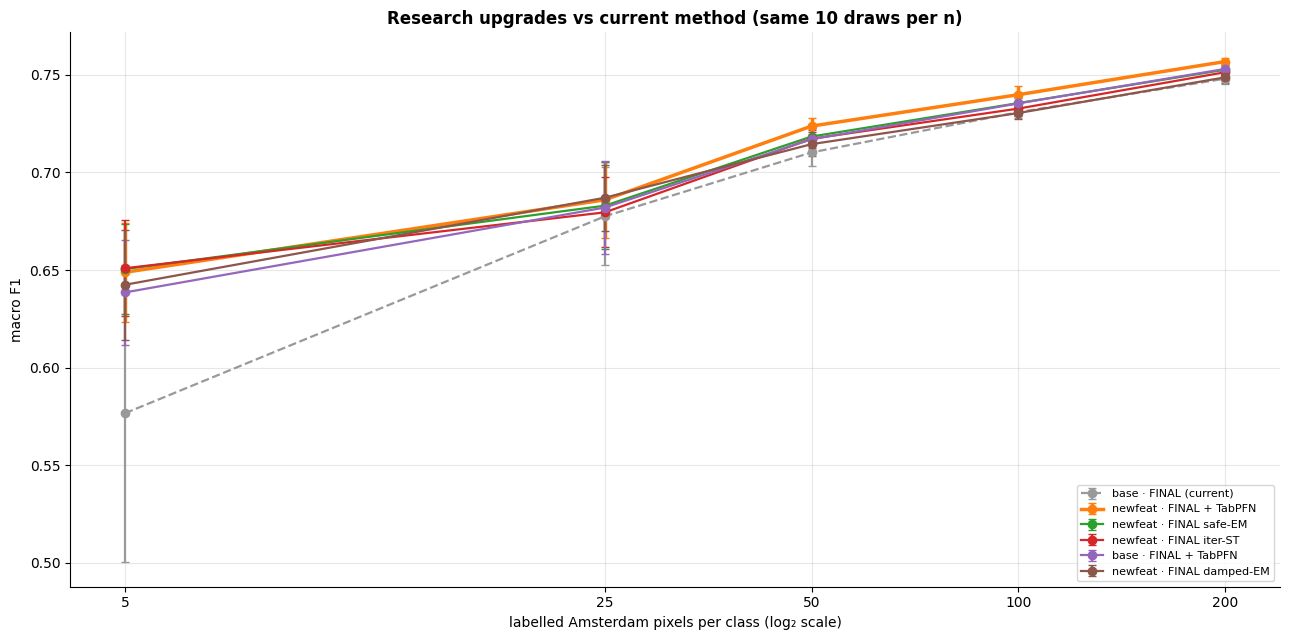

[04:31:15] EXPERIMENTS DONE


In [9]:
fig, ax = plt.subplots(figsize=(13, 6.5)); lx = np.log2(N_SHOTS)
show = [('base', 'FINAL (current)', '#999999', '--')] + [(sp, v, None, '-') for sp, v in dec.index[:5] if (sp, v) != ('base', 'FINAL (current)')]
cols = plt.cm.tab10(np.arange(10))
for i, (sp, v, col, ls) in enumerate(show):
    mu = tab.loc[(sp, v), 'mean'].values; sd = tab.loc[(sp, v), 'std'].values
    ax.errorbar(lx, mu, yerr=sd, marker='o', ls=ls, capsize=3, lw=2.5 if i == 1 else 1.6, color=col or cols[i], label=f'{sp} · {v}')
ax.set_xticks(lx); ax.set_xticklabels(N_SHOTS); ax.set_xlabel('labelled Amsterdam pixels per class (log₂ scale)'); ax.set_ylabel('macro F1')
ax.set_title('Research upgrades vs current method (same 10 draws per n)', fontweight='bold'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(OUT / 'upgrades_vs_current.png', dpi=150, bbox_inches='tight'); plt.show()
log('EXPERIMENTS DONE')

## 8 · Conclusions

*Filled in after the run: which upgrades are adopted into `Building_Age_Final.ipynb`, and which go to "what did not work".*